# А-14-23 Кузнецов Давид
# Лабораторная работа 4

Для модели регрессии
$$
    \eta_i = \varphi_1(X_i) \widetilde{\theta}_1 + \dots + \varphi_m(X_i) \widetilde{\theta}_m + \varepsilon_i , \\
    i = \overline{1,n}
$$
формируется матрица значений базисных функций:
$$
    Z
    = \begin{pmatrix}
        \varphi_1(X_1) & \dots & \varphi_m(X_1) \\
        \vdots & \ddots & \vdots \\
        \varphi_1(X_n) & \dots & \varphi_m(X_n) \\
    \end{pmatrix},
$$
ковариационная матрица $K$ вектора возмущений $\varepsilon = (\varepsilon_1, \dots, \varepsilon_n)$:
$$
    K = D[\varepsilon] = \sigma^2 \overline{K},
$$
и весовая матрица
$$
    \overline{W} = \overline{K}^{-1}.
$$
Для симметричной и положительно определённой матрицы $\overline{W}$ существует разложение Холецкого:
$$
    \overline{W} = R^T R .
$$

Оценка по методу наименьших квадратов $\widehat{\theta}$ является обобщённым решением системы линейных уравнений:
$$
    \widehat{\theta}
    = \arg \min \limits_\theta \left\| \eta - Z \theta \right\|_{\overline{W}}^2
    = \arg \min \limits_\theta \left\| R \eta - R Z \theta \right\|_2^2 .
$$
В Python для нахождения решения можно использовать функцию `numpy.linalg.lstsq`.

Ковариационная матрица оценки:
$$
    D[\widehat{\theta}]
    = \sigma^2 \overline{G}^{-1} , \\
    \overline{G} = Z^T \overline{W} Z .
$$

Оценка $\widehat{\sigma}^2$ остаточной дисперсии $\sigma^2$:
$$
    \widehat{\sigma}^2
    = \frac{\delta(\widehat{\theta})}{n - m} , \\
    \delta(\widehat{\theta}) = \left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2 .
$$

Коэффициент детерминации:
$$
    R^2
    = 1 - \frac{\left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2}{\left\| \eta - U \widehat{c} \right\|_{\overline{W}}^2} , \\
    U = \begin{pmatrix}
        1 \\
        \vdots \\
        1
    \end{pmatrix} , \\
    \widehat{c}
    = \left( U^T W U \right)^{-1} U^T W \eta .
$$

Скорректированный коэффициент детерминации:
$$
    R_{adj}^2
    = 1 - \frac{\frac{1}{n-m} \left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2}{\frac{1}{n-1} \left\| \eta - U \widehat{c} \right\|_{\overline{W}}^2} .
$$

Доверительный интервал для компоненты $\widetilde{\theta}_i$:
$$
    \left(
        \widehat{\theta}_i - y \sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}
        ;
        \widehat{\theta}_i + y \sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}
    \right) , \\
    y = F_T^{-1} \left( \frac{1 + P_g}{2}; n-m \right ) ,
$$
$y$ - квантиль распределения Стьюдента $T(n-m)$ уровня $\frac{1 + P_g}{2}$.

Для проверки гипотезы $H_0: \widetilde{\theta}_i = 0$ против альтернативной $H_1: \widetilde{\theta}_i \neq 0$, используется статистика $t_i$ и критическая
область $\Gamma_\alpha$
$$
    t_i = \frac{\widehat{\theta}_i}{\sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}} , \\
    \Gamma_\alpha = ( -y, y ), \\
    y = F_T^{-1} \left( 1 - \frac{\alpha}{2}; n-m \right ) ,
$$
$y$ - квантиль распределения Стьюдента $T(n-m)$ уровня $1 - \frac{\alpha}{2}$, где $\alpha$ - уровень значимости.

Доверительный интервал для $\sigma^2$ с уровнем доверия $P_g$:
$$
    \left(
        \frac{\delta(\widehat{\theta})}{y_2}
        ;
        \frac{\delta(\widehat{\theta})}{y_1}
    \right) , \\
    y_1 = F_{\chi^2}^{-1} \left( \frac{1 - P_g}{2} ; n - m \right) , \\
    y_2 = F_{\chi^2}^{-1} \left( \frac{1 + P_g}{2} ; n - m \right) ,
$$
$y_1$ и $y_2$ - квантили распределения хи-квадрат $\chi^2(n-m)$.

Доверительная область для $\widetilde{\theta}$ является элипсоидом:
$$
    E(\widehat{\theta}, C)
    = \left\{ \theta: (\theta - \widehat{\theta})^T \overline{G} (\theta - \widehat{\theta}) < C \right\} , \\
    C = y \frac{m}{n-m} \delta(\widehat{\theta}) , \\
    y = F_F^{-1} \left( P_g; m, n-m \right) ,
$$
$y$ - квантиль распределения Фишера $F(m,n-m)$ уровня доверительной вероятности $P_g$.

Для проверки гипотезы $H_0: \widetilde{\theta} = 0$ против $H_1: \widetilde{\theta} \neq 0$ используется статистика $T$ и критическая область $\Gamma_\alpha$:
$$
    T = \frac{n-m}{m} \frac{\left\| Z \widehat{\theta} \right\|_{\overline{W}}^2}{\delta(\widehat{\theta})} , \\
    \Gamma_\alpha = (h_\alpha, + \infty) , \\
    h_\alpha = F_F^{-1} \left( P_g; m, n-m \right) ,
$$
$y$ - квантиль распределения Фишера $F(m,n-m)$ уровня $1-\alpha$, где $\alpha$ - уровень значимости.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)
plt.style.use("seaborn-v0_8-whitegrid")


def fit_wls(Z, eta, sigma2, kbar_diag=None):
    '''Обобщённый МНК для K = sigma2 * Kbar

    kbar_diag хранит диагональ Kbar. Если она не задана,
    то Kbar = I и Wbar = I
    '''
    Z = np.asarray(Z, dtype=float)
    eta = np.asarray(eta, dtype=float)
    n, m = Z.shape

    if kbar_diag is None:
        kbar_diag = np.ones(n)
    kbar_diag = np.asarray(kbar_diag, dtype=float)
    w = 1.0 / kbar_diag

    # R^T R = Wbar
    #Для диагональной Wbar: R = diag(sqrt(w)).
    sqrt_w = np.sqrt(w)
    theta_hat = np.linalg.lstsq(sqrt_w[:, None] * Z, sqrt_w * eta, rcond=None)[0]

    residuals = eta - Z @ theta_hat
    delta = np.sum(w * residuals**2)
    sigma2_hat = delta / (n - m)

    Gbar = Z.T @ (w[:, None] * Z)
    Gbar_inv = np.linalg.inv(Gbar)
    cov_theta = sigma2 * Gbar_inv

    U = np.ones(n)
    c_hat = np.sum(w * eta) / np.sum(w)
    delta_const = np.sum(w * (eta - c_hat * U) ** 2)
    r2 = 1.0 - delta / delta_const
    r2_adj = 1.0 - (delta / (n - m)) / (delta_const / (n - 1))

    return {
        "theta_hat": theta_hat,
        "residuals": residuals,
        "delta": delta,
        "sigma2_hat": sigma2_hat,
        "Gbar": Gbar,
        "Gbar_inv": Gbar_inv,
        "cov_theta": cov_theta,
        "c_hat": c_hat,
        "delta_const": delta_const,
        "r2": r2,
        "r2_adj": r2_adj,
        "weights": w,
        "n": n,
        "m": m,
    }


def print_main_results(result, theta_true=None):
    if theta_true is not None:
        table = pd.DataFrame({
            "истинное theta": theta_true,
            "оценка theta_hat": result["theta_hat"],
            "ошибка": result["theta_hat"] - theta_true,
        }, index=[f"theta_{i}" for i in range(1, len(theta_true) + 1)])
        print(table)
    else:
        print("theta_hat =", result["theta_hat"])
    print("\nD[theta_hat] =")
    print(result["cov_theta"])
    print(f"\nsigma^2_hat = {result['sigma2_hat']:.6f}")
    print(f"R^2 = {result['r2']:.6f}")
    print(f"R^2_adj = {result['r2_adj']:.6f}")

## Задача 1

Выберите случайным образом $n = 50$ точек $x_{i,1}$ на отрезке $[−1,2]$, вычислите
$$
    \eta_i = 1 + 2 x_{i,1} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2)$, $\sigma^2 = 0.25$.

Для модели регрессии
$$
    \eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \varepsilon_i,
$$
считая $K = \sigma^2 I_n$, где $I_n$ - единичная матрица, вычислите:
- оценку по методу наименьших квадратов $\widehat{\theta}$ (сравните с $\widetilde{\theta} = (1, 2)$).
- ковариационную матрицу $D[\widehat{\theta}]$,
- оценку остаточной дисперсии $\widehat{\sigma}^2$ (сравните с $\sigma^2$),
- коэффициент детерминации $R^2$ ,
- постройте доверительные интервалы для $\widetilde{\theta}_1$ и $\widetilde{\theta}_2$ для уровня доверия $P_g = 0.95$,
- проверьте гипотезы $\widetilde{\theta}_1 = 0$ и $\widetilde{\theta}_2 = 0$,
- постройте доверительный интервал для $\sigma^2$ с уровнем значимости $P_g = 0.97$,
- постройте доверительную область для $\widetilde{\theta}$ с уровнем доверия $P_g = 0.9$,
- проверьте гипотезу $\widetilde{\theta} = 0$.

В одной системе координат постройте $n$ точек $(x_{i,1}, \eta_i)$ и отрезки прямых $y = \widetilde{\theta}_1 + \widetilde{\theta}_2 x$ и
$y = \widehat{\theta}_1 + \widehat{\theta}_2 x$ при $x \in [-1, 2]$.

         истинное theta  оценка theta_hat    ошибка
theta_1             1.0          1.003135  0.003135
theta_2             2.0          2.090834  0.090834

D[theta_hat] =
[[ 0.008131 -0.004954]
 [-0.004954  0.007837]]

sigma^2_hat = 0.280566
R^2 = 0.911936
R^2_adj = 0.910101

Интервалы и проверка H0: theta_i = 0


,theta_hat,SE,нижняя граница 95%,верхняя граница 95%,t,p-value,решение при alpha=0.05
theta_1,1.003135,0.095528,0.811063,1.195206,10.500991,4.988748e-14,H0 отвергается
theta_2,2.090834,0.093781,1.902274,2.279394,22.294788,5.667779e-27,H0 отвергается


Доверительный интервал для sigma^2 (Pg=0.97): (0.1879019782011352, 0.4603032936329191)
Доверительная область: (theta-theta_hat)^T Gbar (theta-theta_hat) < 1.356064

H0: theta=0: T=730.112271, F_crit=3.190727, p-value=1.166e-36
Решение: H0 отвергается.


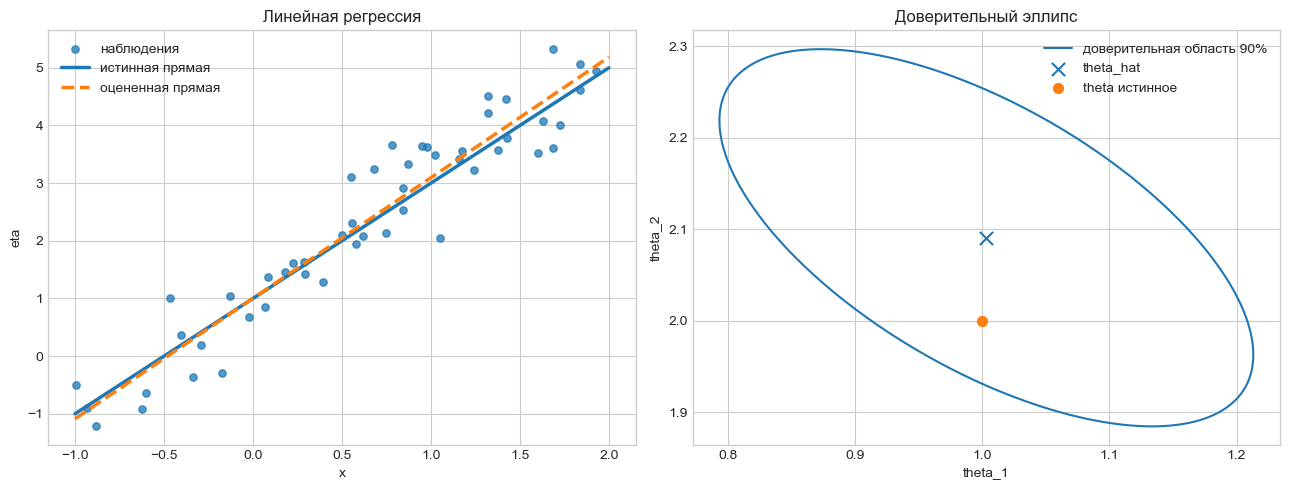

In [9]:
# Задача 1
rng = np.random.default_rng(4101)
n = 50
sigma2 = 0.25
theta_true_1 = np.array([1.0, 2.0])

x = rng.uniform(-1.0, 2.0, n)
epsilon = rng.normal(0.0, np.sqrt(sigma2), n)
eta = theta_true_1[0] + theta_true_1[1] * x + epsilon
Z = np.column_stack((np.ones(n), x))

result_1 = fit_wls(Z, eta, sigma2)
print_main_results(result_1, theta_true_1)

# Доверительные интервалы и t-критерии для компонент theta
Pg_theta = 0.95
alpha = 1.0 - Pg_theta
df = n - Z.shape[1]
t_crit = stats.t.ppf((1.0 + Pg_theta) / 2.0, df)
standard_errors = np.sqrt(np.diag(result_1["Gbar_inv"]) * result_1["sigma2_hat"])
ci_low = result_1["theta_hat"] - t_crit * standard_errors
ci_high = result_1["theta_hat"] + t_crit * standard_errors
t_stat = result_1["theta_hat"] / standard_errors
p_values = 2.0 * stats.t.sf(np.abs(t_stat), df)

inference_table = pd.DataFrame({
    "theta_hat": result_1["theta_hat"],
    "SE": standard_errors,
    "нижняя граница 95%": ci_low,
    "верхняя граница 95%": ci_high,
    "t": t_stat,
    "p-value": p_values,
    "решение при alpha=0.05": np.where(p_values < alpha, "H0 отвергается", "H0 не отвергается"),
}, index=["theta_1", "theta_2"])
print("\nИнтервалы и проверка H0: theta_i = 0")
display(inference_table)

# Доверительный интервал для sigma^2
Pg_sigma = 0.97
chi_low = stats.chi2.ppf((1.0 - Pg_sigma) / 2.0, df)
chi_high = stats.chi2.ppf((1.0 + Pg_sigma) / 2.0, df)
sigma2_interval = (result_1["delta"] / chi_high, result_1["delta"] / chi_low)
print(f"Доверительный интервал для sigma^2 (Pg=0.97): {sigma2_interval}")

# Доверительная область для theta
Pg_region = 0.90
m = Z.shape[1]
f_region = stats.f.ppf(Pg_region, m, n - m)
C = f_region * m / (n - m) * result_1["delta"]
print(f"Доверительная область: (theta-theta_hat)^T Gbar (theta-theta_hat) < {C:.6f}")

# Общая гипотеза H0: theta = 0
fitted_norm2 = result_1["theta_hat"] @ result_1["Gbar"] @ result_1["theta_hat"]
T = (n - m) / m * fitted_norm2 / result_1["delta"]
f_crit = stats.f.ppf(1.0 - alpha, m, n - m)
p_overall = stats.f.sf(T, m, n - m)
print(f"\nH0: theta=0: T={T:.6f}, F_crit={f_crit:.6f}, p-value={p_overall:.3e}")
print("Решение: H0 отвергается." if T > f_crit else "Решение: H0 не отвергается.")

# График и эллипс доверительной области
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x_grid = np.linspace(-1.0, 2.0, 300)
axes[0].scatter(x, eta, s=28, alpha=0.75, label="наблюдения")
axes[0].plot(x_grid, theta_true_1[0] + theta_true_1[1] * x_grid, lw=2.5, label="истинная прямая")
axes[0].plot(x_grid, result_1["theta_hat"][0] + result_1["theta_hat"][1] * x_grid, "--", lw=2.5, label="оцененная прямая")
axes[0].set(xlabel="x", ylabel="eta", title="Линейная регрессия")
axes[0].legend()

eigvals, eigvecs = np.linalg.eigh(result_1["Gbar"])
angles = np.linspace(0, 2 * np.pi, 400)
circle = np.vstack((np.cos(angles), np.sin(angles)))
ellipse = result_1["theta_hat"][:, None] + eigvecs @ np.diag(np.sqrt(C / eigvals)) @ circle
axes[1].plot(ellipse[0], ellipse[1], label="доверительная область 90%")
axes[1].scatter(*result_1["theta_hat"], marker="x", s=90, label="theta_hat")
axes[1].scatter(*theta_true_1, marker="o", s=50, label="theta истинное")
axes[1].set(xlabel="theta_1", ylabel="theta_2", title="Доверительный эллипс")
axes[1].legend()
plt.tight_layout()
plt.show()

### Вывод по задаче 1

Полученная оценка параметров близка к истинному вектору $(1,2)$, а оценка остаточной дисперсии близка к значению $0.25$. Истинные значения параметров входят в построенные доверительные интервалы. В результате проверки гипотезы о равенстве нулю отдельных параметров и всего вектора параметров отвергаются.

## Задача 2

Задайте случайным образом $n = 100$ точек на отрезке $[0, \pi]$ и вычислите
$$
    \eta_i = -1 + 3 x_{i,1} \sin x_{i,1} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2 \cdot \sigma_i^2)$, где $\sigma^2 = 0.1$,
- $\sigma_i = 1 + \frac{x_{i,1}}{\pi}$,
- $\sigma_i = 1 + 3 \frac{x_{i,1}}{\pi}$ .

Для двух наборов $\eta_i$, полученных при двух значениях $\sigma_i$, для модели регрессии
$$
    \eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} \sin x_{i,1} + \varepsilon_i,
$$
считая $K = \sigma^2 \overline{K}$, где $\overline{K}$ - диагональная матрица с элементами $\sigma_i^2$, вычислите:
- оценку по методу наименьших квадратов $\widehat{\theta}$ (сравните с $\widetilde{\theta} = (1, 3)$,
- ковариационную матрицу $D[\widehat{\theta}]$,
- оценку остаточной дисперсии $\widehat{\sigma}^2$ (сравните с $\sigma^2$),
- коэффициент детерминации $R^2$ .

Для каждого из двух вариантов по отдельности в одной системе координат постройте $n$ точек $(x_{i,1}, \eta_i)$ и графики кривых
$y = \widetilde{\theta}_1 + \widetilde{\theta}_2 x \sin x$ и $y = \widehat{\theta}_1 + \widehat{\theta}_2 x \sin x$ для $x \in [0, \pi]$.


sigma_i = 1 + x/pi
         истинное theta  оценка theta_hat    ошибка
theta_1            -1.0         -1.085203 -0.085203
theta_2             3.0          3.055863  0.055863

D[theta_hat] =
[[ 0.006141 -0.004453]
 [-0.004453  0.004857]]

sigma^2_hat = 0.088851
R^2 = 0.956671
R^2_adj = 0.956229

sigma_i = 1 + 3x/pi
         истинное theta  оценка theta_hat    ошибка
theta_1            -1.0         -0.970883  0.029117
theta_2             3.0          2.839277 -0.160723

D[theta_hat] =
[[ 0.00921  -0.00711 ]
 [-0.00711   0.010264]]

sigma^2_hat = 0.092762
R^2 = 0.896267
R^2_adj = 0.895208


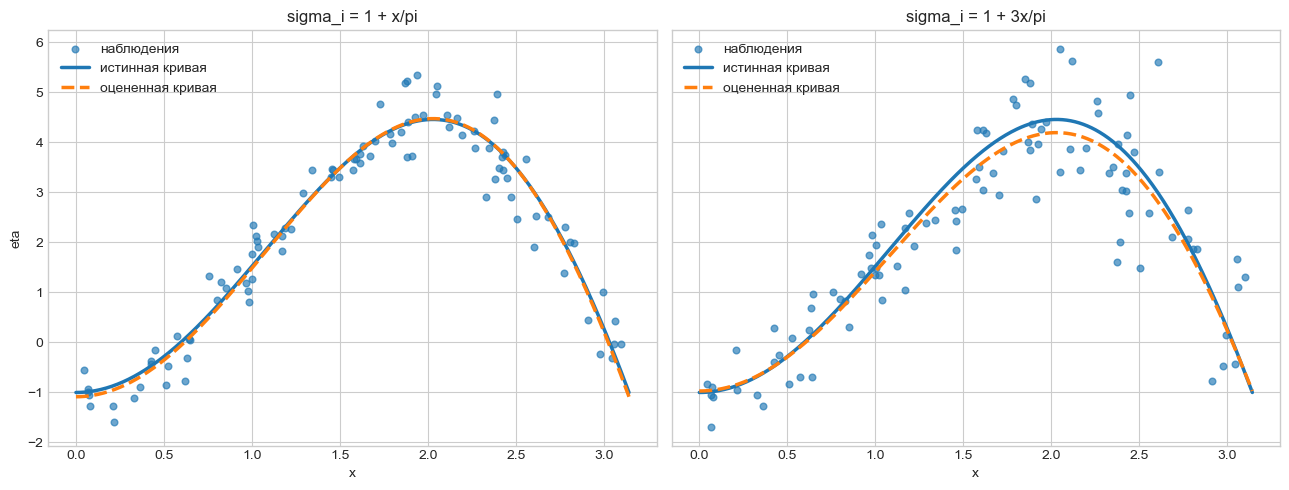

In [21]:
# Задача 2
rng = np.random.default_rng(4102)
n = 100
sigma2 = 0.1
theta_true_2 = np.array([-1.0, 3.0])
x = rng.uniform(0.0, np.pi, n)
phi = x * np.sin(x)
Z = np.column_stack((np.ones(n), phi))

sigma_profiles = {
    "sigma_i = 1 + x/pi": 1.0 + x / np.pi,
    "sigma_i = 1 + 3x/pi": 1.0 + 3.0 * x / np.pi,
}

results_2 = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
x_grid = np.linspace(0.0, np.pi, 400)

for ax, (name, sigma_i) in zip(axes, sigma_profiles.items()):
    epsilon = rng.normal(0.0, np.sqrt(sigma2) * sigma_i, n)
    eta = theta_true_2[0] + theta_true_2[1] * phi + epsilon
    result = fit_wls(Z, eta, sigma2, kbar_diag=sigma_i**2)
    results_2[name] = result

    print(f"\n{name}")
    print_main_results(result, theta_true_2)

    ax.scatter(x, eta, s=23, alpha=0.65, label="наблюдения")
    ax.plot(x_grid, theta_true_2[0] + theta_true_2[1] * x_grid * np.sin(x_grid), lw=2.5, label="истинная кривая")
    ax.plot(x_grid, result["theta_hat"][0] + result["theta_hat"][1] * x_grid * np.sin(x_grid), "--", lw=2.5, label="оцененная кривая")
    ax.set(xlabel="x", title=name)
    ax.legend()

axes[0].set_ylabel("eta")
plt.tight_layout()
plt.show()

### Вывод по задаче 2
В обоих вариантах полученные оценки близки к истинным значениям $(-1,3)$. Во втором варианте случайные ошибки больше, поэтому полученные оценки сильнее отличаются от истинных значений, а коэффициент детерминации $R^2$ становится меньше.

## Задача 3

При $n = 80$ постройте реализацию $(x_{1,1}, \dots, x_{n,1})$ выборки из нормального распределения $\mathcal{N}(1,1)$, реализацию $(x_{1,2}, \dots, x_{n,2})$
выборки из показательного распределения $E(0.5)$ и рассчитайте реализации
$$
    \eta_i = 2 - 3 \xi_{i,1}^2 + x_{i,1} x_{i,2} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей равномерное распределение 𝑅[−1,1].

Считая $K = \sigma^2 I_n$, где $\sigma^2 = 1/3$ и $I_n$ - единичная матрица, для моделей регрессии:
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \widetilde{\theta}_3 x_{i,2} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 + \widetilde{\theta}_3 x_{i,1} x_{i,2} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 + \widetilde{\theta}_3 x_{i,1} x_{i,2} + \widetilde{\theta}_4 x_{i,2}^2 + \varepsilon_i$,

вычислите оценки по методу наименьших квадратов $\widehat{\theta}$ и скорректированные коэффициенты детерминации $R_{adj}^2$.

Определите модель регрессии с наибольшим коэффициентов $R_{adj}^2$ и для неё определите ковариационную матрицу $D[\widehat{\theta}]$ и оценку остаточной дисперсии $\widehat{\sigma}^2$.

In [4]:
# Задача 3
rng = np.random.default_rng(4103)
n = 80
sigma2 = 1.0 / 3.0
x1 = rng.normal(1.0, 1.0, n)
x2 = rng.exponential(scale=1.0 / 0.5, size=n)  # E(lambda=0.5)
epsilon = rng.uniform(-1.0, 1.0, n)
eta = 2.0 - 3.0 * x1**2 + x1 * x2 + epsilon

models_3 = {
    "M1: 1, x1": np.column_stack((np.ones(n), x1)),
    "M2: 1, x1, x2": np.column_stack((np.ones(n), x1, x2)),
    "M3: 1, x1^2, x1*x2": np.column_stack((np.ones(n), x1**2, x1 * x2)),
    "M4: 1, x1^2, x1*x2, x2^2": np.column_stack((np.ones(n), x1**2, x1 * x2, x2**2)),
}

results_3 = {name: fit_wls(Zm, eta, sigma2) for name, Zm in models_3.items()}
comparison_3 = pd.DataFrame({
    "theta_hat": [np.array2string(r["theta_hat"], precision=5) for r in results_3.values()],
    "R^2": [r["r2"] for r in results_3.values()],
    "R^2_adj": [r["r2_adj"] for r in results_3.values()],
    "sigma^2_hat": [r["sigma2_hat"] for r in results_3.values()],
}, index=results_3.keys())
display(comparison_3)

best_name_3 = max(results_3, key=lambda name: results_3[name]["r2_adj"])
best_3 = results_3[best_name_3]
print(f"Лучшая модель: {best_name_3}")
print("D[theta_hat] =")
print(best_3["cov_theta"])
print(f"sigma^2_hat = {best_3['sigma2_hat']:.6f}; истинное sigma^2 = {sigma2:.6f}")

Лучшая модель: M4: 1, x1^2, x1*x2, x2^2
D[theta_hat] =
[[ 0.008906 -0.002584  0.001386 -0.000585]
 [-0.002584  0.002533 -0.002208  0.000532]
 [ 0.001386 -0.002208  0.003703 -0.00102 ]
 [-0.000585  0.000532 -0.00102   0.000344]]
sigma^2_hat = 0.289137; истинное sigma^2 = 0.333333


,theta_hat,R^2,R^2_adj,sigma^2_hat
"M1: 1, x1",[ 2.60113 -3.80005],0.485852,0.479260,11.669012
"M2: 1, x1, x2",[ 0.46801 -4.57596 1.64071],0.732043,0.725083,6.160490
"M3: 1, x1^2, x1*x2",[ 1.89766 -2.98785 0.99548],0.987423,0.987097,0.289142
"M4: 1, x1^2, x1*x2, x2^2",[ 1.92706 -3.01458 1.04672 -0.01729],0.987587,0.987097,0.289137


### Вывод по задаче 3

Наибольшее значение $R_{\mathrm{adj}}^2$ получено для модели с базисными функциями $1$, $x_1^2$, $x_1x_2$ и $x_2^2$. Поэтому для этой модели вычислены ковариационная матрица оценки и оценка остаточной дисперсии. Значения $R_{\mathrm{adj}}^2$ для третьей и четвёртой моделей почти одинаковы, поэтому добавление функции $x_2^2$ практически не изменило качество регрессии.

## Задача 4

Вычислите реализации выборок
$(x_{1,1}, \dots, x_{n,1})$ из нормального распределения $\mathcal{N}(2,4)$,
$(x_{1,2}, \dots, x_{n,2})$ из равномерного распределения $R \left( -\frac{\pi}{2} ; \frac{\pi}{2} \right)$,
$(x_{1,3}, \dots, x_{n,3})$ из показательного распределения $E(0.25)$ и рассчитайте реализации
$$
    \eta_i = 1 + 2 x_{i,1}^2 \cos x_{2,i} - x_{i,2} \ln x_{i,3} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2)$, где $\sigma^2 = 0.25$.

Считая $K = \sigma^2 I_n$, где $I_n$ - единичная матрица, для моделей регрессии:
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \widetilde{\theta}_3 x_{i,2} + \widetilde{\theta}_4 x_{i,3} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 \cos x_{i,2} + \widetilde{\theta}_3 x_{i,2} \ln x_{i,3} + \varepsilon_i$,

вычислите оценки по методу наименьших квадратов $\widehat{\theta}$ и скорректированные коэффициенты детерминации $R_{adj}^2$. Для варианта регрессии с большей
величиной $R_{adj}^2$ вычислите ковариационную матрицу $D[\widehat{\theta}]$, оценку остаточной дисперсии $\sigma^2$ .

In [5]:
# Задача 4
rng = np.random.default_rng(4104)
n = 100  # в условии n не указано
sigma2 = 0.25
x1 = rng.normal(2.0, 2.0, n) 
x2 = rng.uniform(-np.pi / 2.0, np.pi / 2.0, n)
x3 = rng.exponential(scale=1.0 / 0.25, size=n)  # E(lambda=0.25)
epsilon = rng.normal(0.0, np.sqrt(sigma2), n)
eta = 1.0 + 2.0 * x1**2 * np.cos(x2) - x2 * np.log(x3) + epsilon

models_4 = {
    "M1: 1, x1, x2, x3": np.column_stack((np.ones(n), x1, x2, x3)),
    "M2: 1, x1^2*cos(x2), x2*ln(x3)": np.column_stack((np.ones(n), x1**2 * np.cos(x2), x2 * np.log(x3))),
}
results_4 = {name: fit_wls(Zm, eta, sigma2) for name, Zm in models_4.items()}

comparison_4 = pd.DataFrame({
    "theta_hat": [np.array2string(r["theta_hat"], precision=5) for r in results_4.values()],
    "R^2": [r["r2"] for r in results_4.values()],
    "R^2_adj": [r["r2_adj"] for r in results_4.values()],
    "sigma^2_hat": [r["sigma2_hat"] for r in results_4.values()],
}, index=results_4.keys())
display(comparison_4)

best_name_4 = max(results_4, key=lambda name: results_4[name]["r2_adj"])
best_4 = results_4[best_name_4]
print(f"Лучшая модель: {best_name_4}")
print("D[theta_hat] =")
print(best_4["cov_theta"])
print(f"sigma^2_hat = {best_4['sigma2_hat']:.6f}; истинное sigma^2 = {sigma2:.6f}")

Лучшая модель: M2: 1, x1^2*cos(x2), x2*ln(x3)
D[theta_hat] =
[[ 0.003666 -0.000208  0.000204]
 [-0.000208  0.000037 -0.00002 ]
 [ 0.000204 -0.00002   0.00141 ]]
sigma^2_hat = 0.297960; истинное sigma^2 = 0.250000


,theta_hat,R^2,R^2_adj,sigma^2_hat
"M1: 1, x1, x2, x3",[ 2.09044 4.76656 -2.04479 0.06049],0.414441,0.396142,164.417036
"M2: 1, x1^2*cos(x2), x2*ln(x3)",[ 0.97253 2.00875 -1.02655],0.998928,0.998906,0.297960


### Вывод по задаче 4

Наибольшее значение $R_{\mathrm{adj}}^2$ получено для модели с базисными функциями $1$, $x_1^2\cos x_2$ и $x_2\ln x_3$. Оценки её параметров близки к истинным значениям $(1,2,-1)$. Поэтому эта модель лучше воспроизводит наблюдаемые значения $\eta$, чем модель с базисными функциями $1$, $x_1$, $x_2$ и $x_3$.